# Monitoring deserts

Phase M. For every cell of the analysis grid, how far is the nearest monitoring station, and which cells count as a "monitoring desert"? There is no single distance beyond which a station stops being informative (it depends on land use and on the pollutant), so the desert is defined at several thresholds and the results are shown over the whole range. The predicted pollution surface of notebook 11 is then drawn with the stations and the desert on top.

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import yaml

import monitoring_deserts.models.spatial_cv as spatial_cv
import monitoring_deserts.features.deserts as deserts

## Configuration

Read the general project config. The thresholds are a sensitivity parameter: the distance check of notebook 08 found that populated cells are typically far from any station, so the range goes well beyond the 10-50 km named in the plan.

In [4]:
# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)

PROCESSED_DATA_DIR = Path(gen_config["data_dir"]["processed"]) # The data/processed/ should have no subdirs
CLEAN_DATA_DIR = Path(gen_config["data_dir"]["clean"])
MAPS_DIR = Path(gen_config["output_dir"]["maps"]) / "monitoring_deserts"
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "monitoring_deserts"
MAPS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

CELL_SIZE = gen_config["grid_cell_size_deg"]

THRESHOLDS_KM = [10, 25, 50, 100, 200] # desert = if the nearest station is farther than this
MAP_THRESHOLD_KM = 100                 # the one outlined on the pollution map
MIN_MONTHS = 1                         # a station counts as active if it has at least this many months of PM2.5

## Outline

1. ~~**Step 1 - Load the grid, the stations and the predictions.** The grid cells with their population, the stations that have PM2.5 data in the study period, and the mean over the months of the predicted PM2.5 in each cell.~~
2. ~~**Step 2 - Distance to the nearest station.** Great-circle kilometres from every cell to its nearest active station, with the same function as the distance check of notebook 08.~~
3. ~~**Step 3 - The desert at several thresholds.** For each threshold: the number of cells, the area and the population beyond it, and how the predicted PM2.5 in the desert compares with the monitored cells.~~
4. ~~**Step 4 - How much do the conclusions depend on the threshold?** The same statistics over a fine range of thresholds, and the effect of the definition of an active station.~~
5. ~~**Step 5 - Maps.** The distance to the nearest station with the thresholds as contours, and the predicted surface with the stations and the desert outlined.~~
6. ~~**Step 6 - Save.** The distance and desert flags of every cell to `data/processed/`, and the settings and summary to `configs/monitoring_deserts_metadata.yaml`.~~

## Step 1 - Load the grid, the stations and the predictions

A station is active if it has PM2.5 in at least `MIN_MONTHS` months of the study period; with the default of 1 this is every station that contributed to the model. Distances are therefore static: they do not change from month to month (the number of reporting stations varies only a little across months, and the sensitivity to the definition is looked at in Step 4).

In [5]:
analysis_grid = gpd.read_parquet(PROCESSED_DATA_DIR / "grid.parquet")[["cell_id", "centroid_lon", "centroid_lat"]]

# Population per cell (NaN where there is no data), from notebook 06
population = pd.read_parquet(CLEAN_DATA_DIR / "population" / "grid_features.parquet", columns=["cell_id", "population"])

# Mean predicted PM2.5 over the months, per cell (notebook 11)
predicted = (
    pd.read_parquet(PROCESSED_DATA_DIR / "grid_predictions.parquet", columns=["cell_id", "predicted_pm25"])
    .groupby("cell_id")["predicted_pm25"].mean().rename("pm25_mean").reset_index()
)

cells = (
    analysis_grid
    .merge(population, on="cell_id", how="left", validate="one_to_one")
    .merge(predicted, on="cell_id", how="left", validate="one_to_one")
)
cells["area_km2"] = deserts.cell_area_km2(cells["centroid_lat"], CELL_SIZE)

# Stations that have PM2.5 in at least MIN_MONTHS months
station_months = pd.read_parquet(PROCESSED_DATA_DIR / "master_station_df.parquet", columns=["station_id", "longitude", "latitude", "pm25"])
months_with_data = station_months.dropna(subset=["pm25"]).groupby("station_id").size().rename("n_months")
stations = station_months.drop_duplicates("station_id").merge(months_with_data, on="station_id")
active_stations = stations[stations["n_months"] >= MIN_MONTHS]

print(f"{len(cells):,} cells, {cells['population'].isna().sum():,} without population data, {cells['pm25_mean'].isna().sum():,} without a prediction")
print(f"{len(active_stations)} active stations of {len(stations)} with PM2.5 data (MIN_MONTHS = {MIN_MONTHS})")

434,940 cells, 279,850 without population data, 0 without a prediction
343 active stations of 343 with PM2.5 data (MIN_MONTHS = 1)


## Step 2 - Distance to the nearest station

Great-circle kilometres, from a nearest-neighbour search on the sphere (`spatial_cv.nearest_distance_km`), so there is no distortion from working in degrees and no projection to choose. The plan suggested `sjoin_nearest` in an equal-area projection; equal-area projections preserve area, not distance, so the sphere is the more accurate choice for distances.

In [6]:
cells["distance_km"] = spatial_cv.nearest_distance_km(
    cells["centroid_lon"], cells["centroid_lat"],
    active_stations["longitude"], active_stations["latitude"],
)

populated = cells["population"] > 0
spatial_cv.summarize_distances({
    "all cells": cells["distance_km"].to_numpy(),
    "populated cells (population > 0)": cells.loc[populated, "distance_km"].to_numpy(),
}, percentiles=(10, 25, 50, 75, 90))

,10th percentile (km),25th percentile (km),50th percentile (km),75th percentile (km),90th percentile (km),closest (km)
all cells,53.923091,127.051172,428.129145,816.582036,1111.391512,0.137025
populated cells (population > 0),28.721305,51.009615,90.795860,190.363528,374.668023,0.137025


Reading notes: the populated-cell row should agree with the "prediction cells (reality)" row of the distance check in notebook 08 when the same stations are used. The difference between the two rows is that the populated cells are closer to stations than the grid as a whole: stations are in towns, and much of the grid is ocean, desert and mountain.

## Step 3 - The desert at several thresholds

For each threshold, a cell is in the desert if its nearest station is farther away. The table gives the cells, area and people beyond it (people in cells with unknown population are left out, and their number is listed), the mean predicted PM2.5 in the desert and in the monitored cells (also weighted by population), and `prob_desert_higher`: the chance that a random desert cell has a higher predicted PM2.5 than a random monitored one. That last number uses ranks only, so it does not depend on the level of the predictions, which are compressed at high values (plan, Phase J item 5). A value of 0.5 means no difference.

In [7]:
desert_table = deserts.desert_summary(
    cells["distance_km"], THRESHOLDS_KM, cells["area_km2"],
    population=cells["population"], values=cells["pm25_mean"],
)
desert_table.set_index("threshold_km").style.format({
    "share_cells": "{:.1%}", "share_area": "{:.1%}", "share_population": "{:.1%}",
    "desert_area_km2": "{:,.0f}", "desert_population": "{:,.0f}", "n_desert_cells": "{:,}",
    "value_mean_monitored": "{:.1f}", "value_mean_desert": "{:.1f}",
    "value_popweighted_monitored": "{:.1f}", "value_popweighted_desert": "{:.1f}",
    "prob_desert_higher": "{:.3f}",
})

,n_desert_cells,share_cells,desert_area_km2,share_area,desert_population,share_population,desert_cells_without_population,value_mean_monitored,value_popweighted_monitored,value_mean_desert,value_popweighted_desert,prob_desert_higher
threshold_km,,,,,,,,,,,,
10,"432,424",99.4%,"12,237,785",99.4%,"1,571,502,355",87.3%,279841,38.5,40.3,34.1,38.1,0.301
25,"422,428",97.1%,"11,954,334",97.1%,"1,377,694,328",76.5%,279603,37.1,39.8,34.0,38.0,0.341
50,"396,009",91.0%,"11,204,346",91.0%,"1,016,614,658",56.5%,278548,36.1,39.2,33.9,37.8,0.365
100,"344,936",79.3%,"9,750,622",79.2%,"478,786,367",26.6%,274101,35.0,38.3,33.9,38.7,0.405
200,"294,901",67.8%,"8,329,599",67.7%,"167,592,121",9.3%,257788,34.0,38.1,34.2,40.7,0.469


Reading notes: the predicted values are mean predictions in µg/m³ and carry the uncertainty described in notebook 11, so differences of a few µg/m³ between desert and monitored cells are not meaningful on their own; the rank-based column is the safer statement. The cells at the top and the bottom of the threshold range have few cells on one side (almost everything is monitored at a very large threshold, and almost nothing at a very small one), which makes those rows noisier.

## Step 4 - How much do the conclusions depend on the threshold?

The same statistics over a fine range of thresholds show whether a finding is a property of the data or of one chosen number. Then the other arbitrary choice, what counts as an active station, is varied.

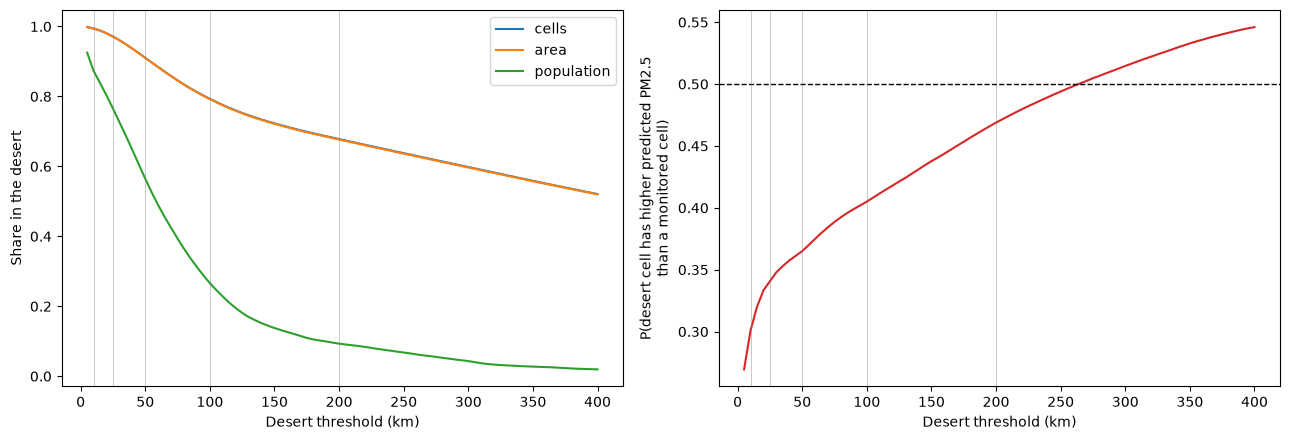

In [8]:
fine_thresholds = np.arange(5, 405, 5)
fine_table = deserts.desert_summary(
    cells["distance_km"], fine_thresholds, cells["area_km2"],
    population=cells["population"], values=cells["pm25_mean"],
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(fine_table["threshold_km"], fine_table["share_cells"], label="cells")
axes[0].plot(fine_table["threshold_km"], fine_table["share_area"], label="area")
axes[0].plot(fine_table["threshold_km"], fine_table["share_population"], label="population")
axes[0].set_xlabel("Desert threshold (km)")
axes[0].set_ylabel("Share in the desert")
axes[0].legend()

axes[1].plot(fine_table["threshold_km"], fine_table["prob_desert_higher"], color="tab:red")
axes[1].axhline(0.5, color="black", linewidth=1, linestyle="--")
axes[1].set_xlabel("Desert threshold (km)")
axes[1].set_ylabel("P(desert cell has higher predicted PM2.5\nthan a monitored cell)")
for ax in axes:
    for t in THRESHOLDS_KM:
        ax.axvline(t, color="grey", linewidth=0.6, alpha=0.5)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "desert_vs_threshold.png", dpi=150)
plt.show()

In [9]:
# Sensitivity to the definition of an active station, at the map threshold
rows = []
for min_months in sorted({m for m in (1, 6, 12, int(months_with_data.max())) if m <= months_with_data.max()}):
    subset = stations[stations["n_months"] >= min_months]
    distance = spatial_cv.nearest_distance_km(cells["centroid_lon"], cells["centroid_lat"], subset["longitude"], subset["latitude"])
    row = deserts.desert_summary(distance, [MAP_THRESHOLD_KM], cells["area_km2"], population=cells["population"], values=cells["pm25_mean"]).iloc[0]
    rows.append({"min_months": min_months, "n_stations": len(subset), "share_cells": row["share_cells"],
                 "share_population": row["share_population"], "prob_desert_higher": row["prob_desert_higher"]})
pd.DataFrame(rows).set_index("min_months").style.format({"share_cells": "{:.1%}", "share_population": "{:.1%}", "prob_desert_higher": "{:.3f}"})

,n_stations,share_cells,share_population,prob_desert_higher
min_months,,,,
1,343,79.3%,26.6%,0.405
6,339,79.6%,27.0%,0.399
12,325,80.1%,29.6%,0.395
16,261,82.2%,35.9%,0.355


Reading notes: a finding is robust if it holds at every threshold of the range with the same sign (for example, the rank-based curve stays on one side of 0.5), not only at the threshold shown on the map. If the curve crosses 0.5, the finding depends on the threshold and should be reported as such. A stricter definition of an active station lowers the station count and pushes the desert outward.

## Step 5 - Maps

The grid's axes and the raster position of every cell are built as in notebooks 06, 10 and 11.

In [10]:
grid_lons = np.sort(cells["centroid_lon"].round(9).unique())
grid_lats = np.sort(cells["centroid_lat"].round(9).unique())
col = np.searchsorted(grid_lons, cells["centroid_lon"].round(9).values)
row = len(grid_lats) - 1 - np.searchsorted(grid_lats, cells["centroid_lat"].round(9).values)
extent = [grid_lons[0] - CELL_SIZE / 2, grid_lons[-1] + CELL_SIZE / 2, grid_lats[0] - CELL_SIZE / 2, grid_lats[-1] + CELL_SIZE / 2]


def to_raster(values):
    """Per-cell values as a north-up raster (row 0 is the northernmost row)."""
    raster = np.full((len(grid_lats), len(grid_lons)), np.nan)
    raster[row, col] = values
    return raster


distance_raster = to_raster(cells["distance_km"].to_numpy())
pm25_raster = to_raster(cells["pm25_mean"].to_numpy())

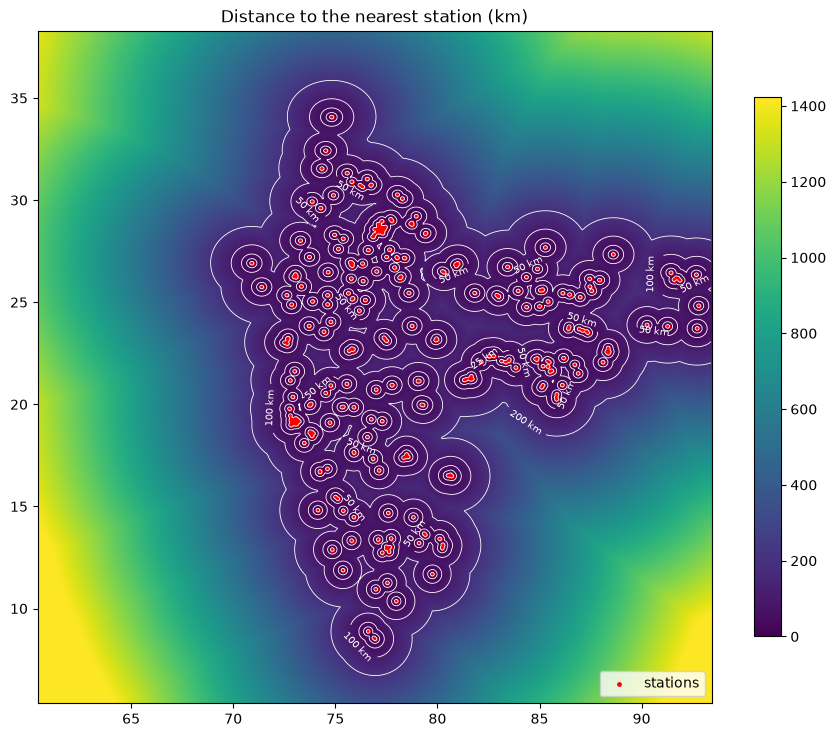

In [11]:
# Distance to the nearest station, with the thresholds as contours
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(distance_raster, extent=extent, cmap="viridis", vmin=0, vmax=np.nanquantile(distance_raster, 0.98))
contours = ax.contour(grid_lons, grid_lats[::-1], distance_raster, levels=THRESHOLDS_KM, colors="white", linewidths=0.6)
ax.clabel(contours, fmt="%d km", fontsize=7)
ax.scatter(active_stations["longitude"], active_stations["latitude"], s=6, color="red", label="stations")
ax.set_title("Distance to the nearest station (km)")
ax.legend(loc="lower right")
fig.colorbar(image, ax=ax, shrink=0.7)
fig.tight_layout()
fig.savefig(MAPS_DIR / "distance_to_nearest_station.png", dpi=150)
plt.show()

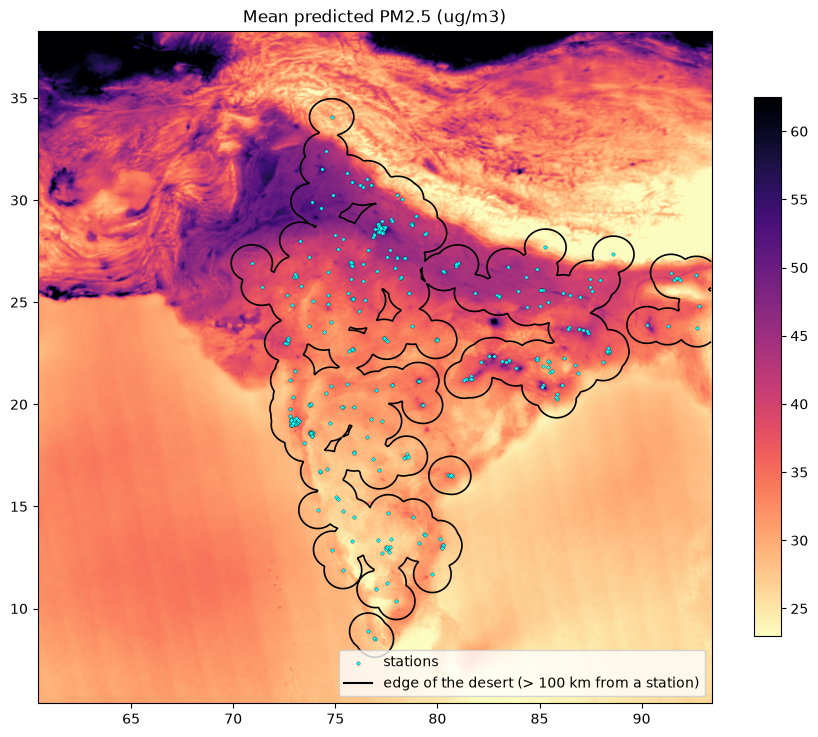

In [12]:
# Predicted PM2.5 (mean over the months) with the stations and the desert outlined
fig, ax = plt.subplots(figsize=(9, 8))
low, high = np.nanquantile(pm25_raster, [0.02, 0.98])
image = ax.imshow(pm25_raster, extent=extent, cmap="magma_r", vmin=low, vmax=high)
ax.contour(grid_lons, grid_lats[::-1], distance_raster, levels=[MAP_THRESHOLD_KM], colors="black", linewidths=1.2)
ax.scatter(active_stations["longitude"], active_stations["latitude"], s=6, color="cyan", edgecolor="black", linewidth=0.2, label="stations")
ax.plot([], [], color="black", label=f"edge of the desert (> {MAP_THRESHOLD_KM} km from a station)")
ax.set_title("Mean predicted PM2.5 (ug/m3)")
ax.legend(loc="lower right")
fig.colorbar(image, ax=ax, shrink=0.7)
fig.tight_layout()
fig.savefig(MAPS_DIR / "predicted_pm25_with_desert.png", dpi=150)
plt.show()

Reading notes: the contour on the second map marks where the distance crosses the threshold; the side away from the stations is the desert. The colour scale is clipped to the 2nd-98th percentile. Cells without a prediction (those missing a feature in notebook 10) are blank, and the map says nothing about them.

## Step 6 - Save

In [13]:
status = cells[["cell_id", "distance_km"]].rename(columns={"distance_km": "distance_to_station_km"})
for t in THRESHOLDS_KM:
    status[f"desert_{t}km"] = cells["distance_km"] > t

STATUS_PATH = PROCESSED_DATA_DIR / "cell_monitoring_status.parquet"
status.to_parquet(STATUS_PATH)

metadata = {
    "distance": "great-circle km to the nearest active station (spatial_cv.nearest_distance_km)",
    "active_station_rule": f"stations with PM2.5 in at least {MIN_MONTHS} month(s) of the study period",
    "n_active_stations": int(len(active_stations)),
    "thresholds_km": [int(t) for t in THRESHOLDS_KM],
    "map_threshold_km": int(MAP_THRESHOLD_KM),
    "grid_cell_size_deg": float(CELL_SIZE),
    "n_cells": int(len(cells)),
    "n_cells_without_population": int(cells["population"].isna().sum()),
    "n_cells_without_prediction": int(cells["pm25_mean"].isna().sum()),
    "summary": [
        {key: (int(value) if isinstance(value, (np.integer,)) else float(value)) for key, value in record.items()}
        for record in desert_table.to_dict(orient="records")
    ],
    "note": "Predicted values carry the uncertainty of notebook 11; prob_desert_higher is rank-based and does not depend on their level.",
    "file": str(STATUS_PATH),
}
with open("../configs/monitoring_deserts_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False)